In [1]:
import pandas as pd

df = pd.read_csv("./ia_tweets.csv")

df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


In [2]:
df.dtypes

ID                            int64
text                         object
polarity                     object
favorite_count                int64
retweet_count                 int64
user_followers_count          int64
user_friends_count            int64
user_favourites_count         int64
user_statuses_count           int64
user_verified                 int64
user_has_extended_profile     int64
user_is_translator            int64
user_protected                int64
user_default_profile          int64
dtype: object

In [5]:
from langdetect import detect, DetectorFactory

DetectorFactory.seed = 0

df['idioma'] = df['text'].apply(detect)

df = df[df["idioma"] == "es"]

df = df.drop(columns=["ID","user_has_extended_profile", "user_is_translator", "user_protected", "idioma"])

In [6]:
def filtrar_por_polaridad(field):
    return df[df["polarity"] == field]

cant_negativos = len(filtrar_por_polaridad("N"))
cant_neutros = len(filtrar_por_polaridad("NEU"))
cant_positivos =  len(filtrar_por_polaridad("P"))

print('Cantidad de tweets: ', len(df))
print('Tweets Negativos: ', cant_negativos, ', Neutros' , cant_neutros,', Positivos', cant_positivos)

# Cantidad de datos desbalanceada, se tiene mucho mas datos neutros que negativos o positivos.

Cantidad de tweets:  3660
Tweets Negativos:  551 , Neutros 2417 , Positivos 692


In [7]:
cantidad_na = df.isna().sum()
print(cantidad_na)

#(cantidad_negativos_columna("favorite_count"))

# No hay nulls o valores

text                     0
polarity                 0
favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


In [9]:
cantidad_negativos = (df.select_dtypes(include='number') < 0).sum()
print(cantidad_negativos)

favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


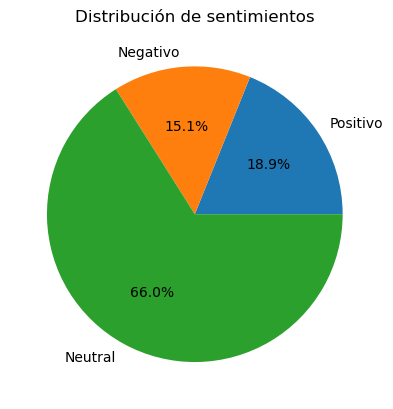

In [10]:
import matplotlib.pyplot as plt

# Datos
clases = ['Positivo', 'Negativo', 'Neutral']
cantidades = [cant_positivos, cant_negativos, cant_neutros]

# Crear gráfico
plt.pie(cantidades, labels=clases, autopct='%1.1f%%')
plt.title('Distribución de sentimientos')
plt.show()

4.1519125683060105
2243
0


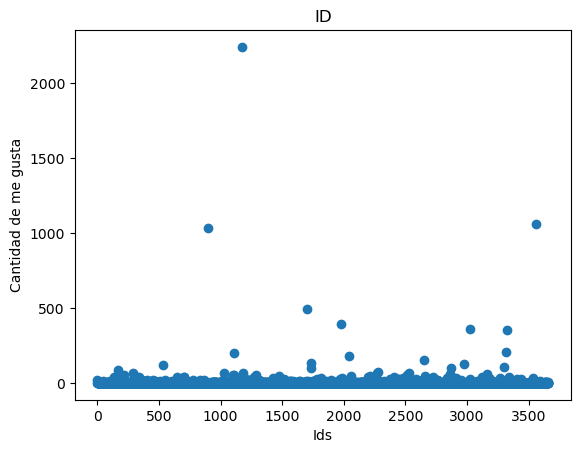

In [11]:
print(df["favorite_count"].mean())
print(df["favorite_count"].max())
print(df["favorite_count"].min())

plt.scatter(range(0,len(df)), df['favorite_count'])

plt.xlabel('Ids')
plt.ylabel('Cantidad de me gusta')
plt.title('ID')

plt.show()

0.9606557377049181
502
0


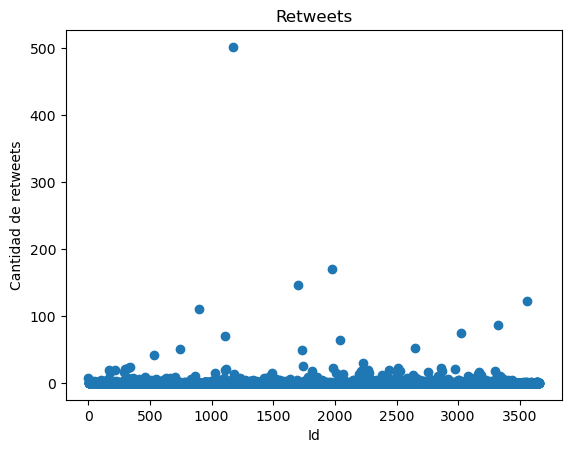

In [12]:
print(df["retweet_count"].mean())
print(df["retweet_count"].max())
print(df["retweet_count"].min())

plt.scatter(range(0,len(df)), df['retweet_count'])

plt.xlabel('Id')
plt.ylabel('Cantidad de retweets')
plt.title('Retweets')

plt.show()

Cantidad de tweets positivo con interaccion:  172
Cantidad de tweets negativos con interaccion:  139
Media de interacciones en positivos:  6.726878612716763
Media de interacciones en negativos:  3.8747731397459164


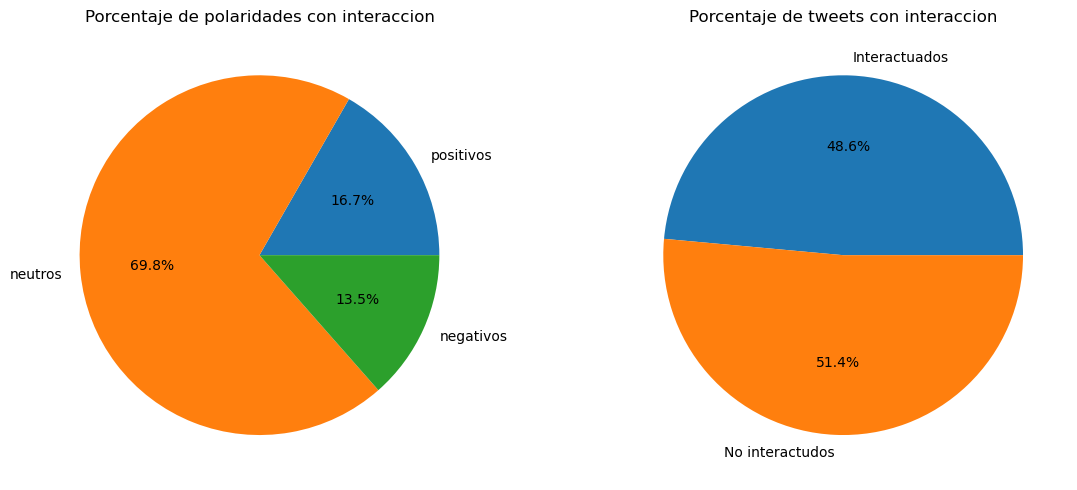

In [13]:
df['tweet_interactions'] = df['favorite_count'] + df['retweet_count']

tweets_con_interaccion = (df['tweet_interactions'] > 0).sum()
tweets_sin_interaccion = (df['tweet_interactions'] == 0).sum()

positivos_con_interaccion = (df[df['polarity'] == 'P']['tweet_interactions'] > 1).sum()
neutros_con_interaccion = (df[df['polarity'] == 'NEU']['tweet_interactions'] > 1).sum()
negativos_con_interaccion = (df[df['polarity'] == 'N']['tweet_interactions'] > 1).sum()
interaccion_positivos_media = df[df['polarity'] == 'P']['tweet_interactions'].mean()
interaccion_negativos_media = df[df['polarity'] == 'N']['tweet_interactions'].mean()

print("Cantidad de tweets positivo con interaccion: ", positivos_con_interaccion)
print("Cantidad de tweets negativos con interaccion: ", negativos_con_interaccion)
print("Media de interacciones en positivos: ", interaccion_positivos_media)
print("Media de interacciones en negativos: ", interaccion_negativos_media)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].pie([positivos_con_interaccion, neutros_con_interaccion, negativos_con_interaccion], labels=["positivos", "neutros", "negativos"], autopct='%1.1f%%')
ax[0].set_title('Porcentaje de polaridades con interaccion')

ax[1].pie([tweets_con_interaccion, tweets_sin_interaccion],
  labels=["Interactuados", "No interactudos"], autopct='%1.1f%%')
ax[1].set_title('Porcentaje de tweets con interaccion')

plt.tight_layout()
plt.show()

In [14]:
 #text
#polarity
#favorite_count
#retweet_count
#user_followers_count
#user_friends_count
#user_favourites_count         TEST (Likes que dio)
#user_statuses_count           TEST (Publicaciones y comentarios suyos)
#user_verified                 TEST
#user_default_profile          TEST (Pagina de perfil default)

import unicodedata

def contar_emojis(texto):
    return sum(1 for caracter in str(texto) if unicodedata.category(caracter) == 'So')

df["length"] = df['text'].apply(lambda texto: len(texto.split()))
df["hashtag_count"] = df['text'].apply(lambda texto: texto.count('#'))
df["mention_count"] = df['text'].apply(lambda texto: texto.count('@'))
df["url_count"] = df['text'].apply(lambda texto: texto.count('http'))
df["punctuation_count"] = df['text'].apply(lambda texto: texto.count('?') + texto.count('!'))
df['emoji_count'] = df['text'].apply(contar_emojis)

# :url: :mencion:

#Campos extra
#Longitud (palabras)
#Cantidad de hashtags
#Cantidad de usuarios mencionados
#Cantidad de emojis
#Cantidad de urls
#Cantidad de signos de exclamacion/interrogacion

In [15]:
df["text"] = df["text"].str.replace(r"http\S+|www\.\S+", "URL", regex=True)
df["text"] = df["text"].str.replace(r"@\w+", "MENCION", regex=True)

df.head()

,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_default_profile,tweet_interactions,length,hashtag_count,mention_count,url_count,punctuation_count,emoji_count
0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,0,28,44,0,0,1,0,0
1,"MENCION Eso es imposible. Y sí, va a generar u...",N,1,0,685,851,169490,128555,0,1,1,41,0,1,0,0,0
2,MENCION Lo disruptivo es que tras años de deci...,NEU,1,0,685,851,169490,128555,0,1,1,39,0,1,0,0,0
3,"MENCION ¿""Prohibición del uso comercial de las...",N,0,0,4877,538,6123,3156,0,0,0,17,0,1,0,1,0
4,MENCION Cómo se está estudiando prohibir chatG...,NEU,0,0,15936,2395,66945,68578,0,0,0,39,0,1,0,1,0


In [16]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["polarity"])
y = df["polarity"]

# 60% para train y 40% para test y validacion
X_train, X_test_val, y_train, y_test_val = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Segunda división: separar test y validación
X_test, X_val, y_test, y_val = train_test_split(
    X_test_val, y_test_val,
    test_size=0.5,
    random_state=42,
    stratify=y_test_val
)

print(len(X_train)/len(df))

0.6


In [17]:
from sklearn.preprocessing import StandardScaler

number_columns = ["favorite_count","retweet_count","user_followers_count", "user_friends_count", "user_favourites_count", "user_statuses_count", "tweet_interactions", "hashtag_count", "mention_count"]

scaler = StandardScaler()

X_train[number_columns] = scaler.fit_transform(X_train[number_columns])

y_train = pd.get_dummies(y_train, columns=["polarity"], dtype=int, drop_first=True)

X_train.head()
y_train.head()

,NEU,P
1468,1,0
3145,1,0
2137,1,0
3883,1,0
2562,1,0


In [19]:
from sklearn.base import BaseEstimator, TransformerMixin
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
import string

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')
stop_words = set(stopwords.words('spanish'))

class TextCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, method=None):
        self.method = method

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # Inicializamos dentro de transform para evitar errores de multiprocessing
        stop_words = set(stopwords.words('spanish'))
        punctuation = set(string.punctuation)
        stemmer = PorterStemmer()
        lemmatizer = WordNetLemmatizer()

        clean_X = []
        for text in X:
            # 1. Minúsculas y Tokenización
            tokens = nltk.word_tokenize(text.lower())

            # 2. Remover Stopwords y Puntuación
            tokens = [t for t in tokens if t not in stop_words and t not in punctuation]

            # 3. Reducción a raíz (Stemming o Lemmatization)
            if self.method == 'stem':
                tokens = [stemmer.stem(t) for t in tokens]
            elif self.method == 'lemma':
                tokens = [lemmatizer.lemmatize(t) for t in tokens]

            clean_X.append(" ".join(tokens))
        return clean_X

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ianra\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ianra\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ianra\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [21]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

cleaner = TextCleaner("lemma")

vectores = cleaner.transform(df["text"])
vectorizer_BoW = CountVectorizer()
vectorizer_Tfidf = TfidfVectorizer()


matriz_BoW = vectorizer_BoW.fit_transform(vectores)
matriz_Tfidf = vectorizer_Tfidf.fit_transform(vectores)

print(vectorizer_BoW.get_feature_names_out())
print(matriz_BoW.toarray()[0])
#print(vectores_Tfidf.shape)

['00' '000' '003' ... '𝙀𝙣𝙩𝙧𝙚𝙥𝙖𝙧𝙦𝙪𝙚𝙨' '𝙈𝙤𝙣𝙩𝙚𝙨𝙪𝙧' '𝙈𝙤𝙣𝙩𝙞𝙚𝙡']
[0 0 0 ... 0 0 0]


In [ ]:
from sentence_transformers import SentenceTransformer # <- Estandar para Embeddings

class EmbeddingTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, model_name='all-MiniLM-L6-v2'):
        self.model_name = model_name
        self.model = None

    def fit(self, X, y=None):
        # Cargamos el modelo aquí para evitar errores de serialización
        if self.model is None:
            self.model = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        # Convertimos la lista de textos en una matriz de vectores (Embeddings)
        # Esto implementa implícitamente el "Mean Pooling"
        return self.model.encode(list(X), show_progress_bar=False)

embedding = EmbeddingTransformer()

In [54]:
embedding.fit(df["text"])
text = embedding.transform(df["text"])
print(text.shape)
print(text)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

c:\Users\ianra\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ianra\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

(3660, 384)
[[ 0.15161388  0.13791277 -0.15399662 ... -0.23173821  0.18059723
   0.0793908 ]
 [-0.0579738  -0.24207363  0.10032641 ... -0.01575601  0.21499768
  -0.1127634 ]
 [-0.06540351 -0.1785775   0.19099699 ...  0.0810954   0.4012917
   0.07221723]
 ...
 [-0.26395085 -0.03915965 -0.14702234 ... -0.07476877 -0.22752364
   0.05211059]
 [-0.06131363 -0.00176563  0.16047071 ... -0.01875061 -0.07580701
  -0.18729647]
 [ 0.05583207 -0.19120212 -0.01426136 ...  0.01424005 -0.07063261
   0.05583804]]


In [30]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

X_train, X_test, y_train, y_test = train_test_split(df['text'], df['polarity'], test_size=0.2, random_state=42)

# El Pipeline combina el vectorizador y el clasificador
pipeline = Pipeline([
    ('cleaner', TextCleaner()), # Nuestro Transformador
    ('vectorizer', CountVectorizer()), # BoW inicial
    ('classifier', MultinomialNB())
])

# Parámetros a tunear
param_grid = [
    # Opción 1: Naive Bayes con distintas vectorizaciones y n-gramas
    {
        'cleaner__method': [None, 'stem', 'lemma'],
        'vectorizer': [CountVectorizer(), TfidfVectorizer()],
        'vectorizer__ngram_range': [(1, 1), (1, 2)], # Unigramas vs Bigramas
        'classifier': [MultinomialNB()], # Muy bueno cuando se trabaja con Tf-Idf o BoW
        'classifier__alpha': [0.1, 1.0]
    },
    # Opción 2: Regresión Logística
    {
        'cleaner__method': ['lemma'],
        'vectorizer': [TfidfVectorizer()],
        'classifier': [LogisticRegression()],
        'classifier__C': [1, 10]
    }
]

# Ejecución del Grid Search optimizando roc-auc
grid_search = GridSearchCV(pipeline, param_grid, cv=2, scoring='roc_auc', n_jobs=1, verbose=1)
grid_search.fit(X_train, y_train)

Fitting 2 folds for each of 26 candidates, totalling 52 fits


c:\Users\ianra\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:953: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "c:\Users\ianra\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 942, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
  File "c:\Users\ianra\anaconda3\Lib\site-packages\sklearn\metrics\_scorer.py", line 308, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\ianra\anaconda3\Lib\site-packages\sklearn\metrics\_scorer.py", line 408, in _score
    return self._sign * self._score_func(y_true, y_pred, **scoring_kwargs)
                        ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\ianra\anaconda3\Lib\site-packages\sklearn\uti

,estimator,Pipeline(step...inomialNB())])
,param_grid,"[{'classifier': [MultinomialNB()], 'classifier__alpha': [0.1, 1.0], 'cleaner__method': [None, 'stem', ...], 'vectorizer': [CountVectorizer(), TfidfVectorizer()], ...}, {'classifier': [LogisticRegression()], 'classifier__C': [1, 10], 'cleaner__method': ['lemma'], 'vectorizer': [TfidfVectorizer()]}]"
,scoring,'roc_auc'
,n_jobs,1
,refit,True
,cv,2
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,method,None


In [57]:
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import classification_report, roc_auc_score

X = df["text"]
y = df["polarity"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

pipeline = Pipeline([
    ("cleaner", TextCleaner()),
    ("vectorizer", CountVectorizer()),
    ("classifier", LogisticRegression(max_iter=3000, random_state=42, class_weight="balanced")),
])

param_grid = [
    {
        "cleaner__method": [None, "stem"],
        "vectorizer": [TfidfVectorizer()],
        "vectorizer__ngram_range": [(1, 1), (1, 2)],
        "vectorizer__min_df": [2],
        "vectorizer__max_df": [0.5, 0.8, 1.0],
        "vectorizer__sublinear_tf": [True, False],
        "classifier__C": [0.5, 1, 2],
        "classifier__class_weight": [None, "balanced"],
    },
    {   
        "vectorizer": [CountVectorizer()],
        "vectorizer__ngram_range": [(1, 1), (1, 2)],
        "vectorizer__min_df": [2],
        "vectorizer__max_df": [0.5, 0.8, 1.0],
        "cleaner__method": [None, "stem"],
        "classifier__C": [0.5, 1, 2],
        "classifier__class_weight": [None, "balanced"],
    },
]

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=3,
    scoring={
        "f1_macro": "f1_macro",
        "roc_auc_ovr": "roc_auc_ovr",
    },
    refit="roc_auc_ovr",    
    n_jobs=1,
    verbose=1,
)   

grid_search.fit(X_train, y_train)

idx = grid_search.best_index_

print("Mejores parámetros:", grid_search.best_params_)

print("Mejor F1 macro (validación cruzada):", grid_search.cv_results_["mean_test_f1_macro"][idx])
print("Mejor ROC-AUC OvR:", grid_search.best_score_)


proba = grid_search.predict_proba(X_test)
print("ROC-AUC test (TF-IDF):", roc_auc_score(y_test, proba, multi_class="ovr"))
print(classification_report(y_test, grid_search.predict(X_test)))

Fitting 3 folds for each of 216 candidates, totalling 648 fits
Mejores parámetros: {'classifier__C': 0.5, 'classifier__class_weight': 'balanced', 'cleaner__method': 'stem', 'vectorizer': TfidfVectorizer(), 'vectorizer__max_df': 0.5, 'vectorizer__min_df': 2, 'vectorizer__ngram_range': (1, 1), 'vectorizer__sublinear_tf': True}
Mejor F1 macro (validación cruzada): 0.5681074108816316
Mejor ROC-AUC OvR: 0.7678327860719815
ROC-AUC test (TF-IDF): 0.7785883556203538
              precision    recall  f1-score   support

           N       0.37      0.59      0.46       110
         NEU       0.77      0.62      0.69       484
           P       0.47      0.59      0.52       138

    accuracy                           0.61       732
   macro avg       0.54      0.60      0.56       732
weighted avg       0.66      0.61      0.62       732



In [56]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

scoring = {"f1_macro": "f1_macro", "roc_auc_ovr": "roc_auc_ovr"}

embedding = EmbeddingTransformer(model_name="paraphrase-multilingual-mpnet-base-v2")
print("Modelo:", embedding.model_name)
embedding.fit(X_train)

emb_train = embedding.transform(X_train)
emb_test = embedding.transform(X_test)
print(emb_train.shape, emb_test.shape)

param_grid_emb = {
    "C": [0.01, 0.03, 0.1, 0.3, 1],
    "class_weight": [None, "balanced"],
}

grid_emb = GridSearchCV(
    LogisticRegression(max_iter=3000, random_state=42),
    param_grid_emb,
    cv=3,
    scoring=scoring,
    refit="roc_auc_ovr",
    n_jobs=1,
    verbose=1,
)
grid_emb.fit(emb_train, y_train)

idx = grid_emb.best_index_
print("Mejores parámetros:", grid_emb.best_params_)
print("F1 macro (CV):", grid_emb.cv_results_["mean_test_f1_macro"][idx])
print("ROC-AUC (CV):", grid_emb.best_score_)


proba_emb = grid_emb.predict_proba(emb_test)
print("ROC-AUC test (embeddings):", roc_auc_score(y_test, proba_emb, multi_class="ovr"))
print(classification_report(y_test, grid_emb.predict(emb_test)))

Modelo: paraphrase-multilingual-mpnet-base-v2


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

c:\Users\ianra\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ianra\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-mpnet-base-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.12k [00:00<?, ?B/s]

...

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

(2928, 768) (732, 768)
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Mejores parámetros: {'C': 0.3, 'class_weight': None}
F1 macro (CV): 0.6852207069380308
ROC-AUC (CV): 0.8911100068770798
ROC-AUC test (embeddings): 0.8780143521837257
              precision    recall  f1-score   support

           N       0.70      0.51      0.59       110
         NEU       0.81      0.89      0.84       484
           P       0.74      0.63      0.68       138

    accuracy                           0.78       732
   macro avg       0.75      0.68      0.70       732
weighted avg       0.78      0.78      0.78       732

